
### Edited Results 1 


This notebook recomputes the biological annotation of the leading developmental PCs used in the first Results subsection.

**Purpose.** The previous manuscript described specific biological associations for `CLS_devPC3` and `CLS_devPC10`, but those annotations were obtained from the historical pre-audit embedding. Because AE1b retrained the definitive MLM and AE2 recomputed the developmental PCA, individual PC numbers can rotate, reorder, or flip sign. Those old PC-specific statements therefore should **not** be carried into the revised manuscript without recomputation.

This notebook:

1. reads the **AE1b** and the definitive clean developmental AnnData;
2. uses the saved deterministic CLS embeddings from the **joint MLM seed 17** (primary representation);
3. reproduces the developmental PCA used by AE2 and checks the known dimensionality results;
4. scores the same curated developmental programs used in the previous biological annotation, but on **log1p library-normalized expression**;
5. correlates the first 10 developmental PCs with curated program scores using Spearman correlation;
6. calculates genome-wide gene–PC correlations on the same normalized expression matrix;
7. explicitly checks the genes/programs used in the previous PC3/PC10 wording;
8. repeats the program-level analysis for **joint seed 42** as a robustness check, without assuming PC-number correspondence across seeds;
9. writes a replacement Fig. 1B heatmap and manuscript-ready tables.

(*note that in the notebook last running AE was labeled WP, work_package*)

#### Interpretation rule

PC signs are arbitrary. A sign flip does **not** imply a biological disagreement. Across seeds, compare the presence/strength of biological programs in the leading developmental space, not the identity of a numbered PC.



In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

import scanpy as sc
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

DATA_ROOT = Path("/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data")
AUDITED_ROOT = DATA_ROOT / "revision_audited_mlm"
MANIFEST_PATH = AUDITED_ROOT / "manifest.json"

OUTDIR = AUDITED_ROOT / "analysis" / "edited_results_1_developmental_PC_annotation"
OUTDIR.mkdir(parents=True, exist_ok=True)

PRIMARY_SEED = 17
ROBUSTNESS_SEED = 42
N_PCS_ANNOTATE = 10
K_FIXED = 75
TARGET_SUM = 1e4
MIN_PROGRAM_GENES = 2
MIN_GENE_DETECTION_FRACTION = 0.01

print("Manifest:", MANIFEST_PATH)
print("Outputs :", OUTDIR)


Manifest: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/manifest.json
Outputs : /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_results_1_developmental_PC_annotation


In [ ]:

# Load reviewed manifest, clean developmental object, and authoritative
# saved CLS embeddings. No model inference/retraining occurs here.
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH}\nRun the definitive AE1b notebook first."
    )

with open(MANIFEST_PATH) as f:
    manifest = json.load(f)

DEV_H5AD = Path(manifest["dev_h5ad"])
A_dev = sc.read_h5ad(DEV_H5AD)

assert A_dev.n_obs == 34760, f"Unexpected developmental cell count: {A_dev.n_obs}"
assert A_dev.n_vars == 15376, f"Unexpected aligned gene count: {A_dev.n_vars}"

def load_joint_dev_embedding(seed):
    model_dir = Path(manifest["models"]["joint"][str(seed)])
    emb_path = model_dir / "X_dev_cls.npy"
    names_path = model_dir / "dev_obs_names.npy"

    if not emb_path.exists():
        raise FileNotFoundError(emb_path)
    if not names_path.exists():
        raise FileNotFoundError(names_path)

    X = np.load(emb_path)
    names = np.load(names_path, allow_pickle=True).astype(str)

    assert X.shape == (A_dev.n_obs, 256), f"Unexpected CLS shape for seed {seed}: {X.shape}"
    assert np.array_equal(names, A_dev.obs_names.astype(str).to_numpy()), (
        f"Developmental observation order does not match for joint seed {seed}."
    )
    assert np.isfinite(X).all()

    return model_dir, X

MODEL17, X_dev17 = load_joint_dev_embedding(PRIMARY_SEED)
MODEL42, X_dev42 = load_joint_dev_embedding(ROBUSTNESS_SEED)

print("Developmental AnnData:", A_dev.shape)
print("Joint seed 17:", MODEL17, X_dev17.shape)
print("Joint seed 42:", MODEL42, X_dev42.shape)
print("Observation-name alignment checks: PASS")

if "dev_state_union" in A_dev.obs:
    print("\nBalanced developmental composition:")
    print(A_dev.obs["dev_state_union"].astype(str).value_counts())


Developmental AnnData: (34760, 15376)
Joint seed 17: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_17/model (34760, 256)
Joint seed 42: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_42/model (34760, 256)
Observation-name alignment checks: PASS

Balanced developmental composition:
dev_state_union
gut_epithelium_distal               4000
ductal                              4000
lung_progenitor                     4000
lung_airway                         4000
gut_epithelium_proximal_or_mixed    4000
liver_hepatocyte                    4000
foregut_other                       3948
acinar_or_tip                       3747
biliary                             1742
non_epithelial_endocrine            1323
Name: count, dtype: int64



## Expression preprocessing for biological annotation

The aligned developmental matrix is count-like. For biological program scoring and gene–axis correlations we therefore use **library-size normalization to 10,000 counts followed by `log1p`**, matching the normalization convention used for the audited program analyses in AE2/AE5.

The matrix remains sparse; the notebook does not densify the full 34,760 × 15,376 expression matrix.


In [3]:

X_raw = A_dev.X
if sp.issparse(X_raw):
    X_raw = X_raw.tocsr().astype(np.float32)
    totals = np.asarray(X_raw.sum(axis=1)).ravel()
    detected = np.asarray((X_raw > 0).sum(axis=1)).ravel()
else:
    X_raw = np.asarray(X_raw, dtype=np.float32)
    totals = X_raw.sum(axis=1)
    detected = (X_raw > 0).sum(axis=1)

assert np.all(np.isfinite(totals))
assert np.all(totals >= 0)

if sp.issparse(X_raw):
    scale = TARGET_SUM / np.maximum(totals, 1.0)
    X_log = sp.diags(scale.astype(np.float32)) @ X_raw
    X_log = X_log.tocsr()
    X_log.data = np.log1p(X_log.data)
    detection_fraction = np.asarray((X_raw > 0).sum(axis=0)).ravel() / A_dev.n_obs
else:
    scale = TARGET_SUM / np.maximum(totals, 1.0)
    X_log = np.log1p(X_raw * scale[:, None])
    detection_fraction = (X_raw > 0).mean(axis=0)

print("Total-count range:", float(totals.min()), "to", float(totals.max()))
print("Median detected genes:", float(np.median(detected)))
print("Expression normalization: log1p(counts / library_size * 1e4)")


Total-count range: 373.0 to 30192.0
Median detected genes: 1493.5
Expression normalization: log1p(counts / library_size * 1e4)



## Curated developmental programs

These are the same core mouse programs used in the previous biological annotation notebook. They are used here as **descriptive biological summaries**, not as mutually exclusive cell identities.

Note that `acinar_differentiation` and `secretory_digestive_enzyme_program` deliberately overlap strongly; they should not be interpreted as independent biological processes.


In [4]:

PROGRAMS_MOUSE = {
    "foregut_early_epithelial_identity": [
        "Sox2", "Sox9", "Foxa1", "Foxa2", "Hnf1b",
        "Krt8", "Krt18", "Epcam", "Cldn4"
    ],
    "ductal_differentiation": [
        "Krt19", "Krt7", "Sox9", "Cftr", "Muc1",
        "Mmp7", "Slc4a4", "Anxa4", "Cldn10", "Hnf1b"
    ],
    "acinar_differentiation": [
        "Prss1", "Prss2", "Cela2a", "Cela3b",
        "Cpa1", "Cpa2", "Cpb1", "Ctrb1",
        "Reg1", "Reg2", "Pnlip", "Clps", "Amy2a5"
    ],
    "biliary_like_differentiation": [
        "Krt7", "Krt19", "Sox9", "Epcam", "Muc1",
        "Tff1", "Tff2", "Slc4a2", "Anxa4",
        "Cldn4", "Cldn10", "Hnf1b"
    ],
    "proliferation_cell_cycle": [
        "Mki67", "Top2a", "Pcna", "Mcm2", "Mcm3", "Mcm4",
        "Mcm5", "Mcm6", "Mcm7", "Cdk1", "Ccnb1",
        "Ccnb2", "Ube2c", "Birc5"
    ],
    "morphogenesis_epithelial_maturation": [
        "Epcam", "Krt8", "Krt18", "Krt19", "Cdh1",
        "Cldn3", "Cldn4", "Ocln", "Tjp1",
        "Itga6", "Lamc2"
    ],
    "secretory_digestive_enzyme_program": [
        "Prss1", "Prss2", "Cela2a", "Cela3b",
        "Cpa1", "Cpa2", "Cpb1", "Ctrb1",
        "Pnlip", "Clps", "Amy2a5"
    ],
    "progenitor_fetal_like_program": [
        "Sox9", "Prom1", "Aldh1a1", "Aldh1a3",
        "Nes", "Tff1", "Tff2",
        "S100a10", "Lgals1", "Vim"
    ],
    "neuroendocrine_like_peptide_hormone": [
        "Chga", "Chgb", "Scg2", "Scg3", "Scg5",
        "Snap25", "Syt1", "Syt4", "Syt13", "Rab3a", "Rab3b",
        "Neurod1", "Fev", "Isl1", "Pax6", "Nkx2-2",
        "Gip", "Cck", "Gast", "Tph1", "Penk", "Resp18"
    ],
}

if "symbol" in A_dev.var.columns:
    symbols = A_dev.var["symbol"].astype(str).to_numpy()
else:
    warnings.warn("A_dev.var['symbol'] not found; using var_names as symbols.")
    symbols = A_dev.var_names.astype(str).to_numpy()

gene_to_idx = {}
for i, g in enumerate(symbols):
    gene_to_idx.setdefault(g, i)

coverage_rows = []
for pname, genes in PROGRAMS_MOUSE.items():
    present = [g for g in genes if g in gene_to_idx]
    missing = [g for g in genes if g not in gene_to_idx]
    coverage_rows.append({
        "program": pname,
        "n_total": len(genes),
        "n_present": len(present),
        "fraction_present": len(present) / len(genes),
        "present_genes": ", ".join(present),
        "missing_genes": ", ".join(missing),
    })

program_coverage = pd.DataFrame(coverage_rows)
program_coverage.to_csv(OUTDIR / "edited_results_1_program_marker_coverage.csv", index=False)
display(program_coverage)


,program,n_total,n_present,fraction_present,present_genes,missing_genes
0,foregut_early_epithelial_identity,9,9,1.0,"Sox2, Sox9, Foxa1, Foxa2, Hnf1b, Krt8, Krt18, ...",
1,ductal_differentiation,10,10,1.0,"Krt19, Krt7, Sox9, Cftr, Muc1, Mmp7, Slc4a4, A...",
2,acinar_differentiation,13,13,1.0,"Prss1, Prss2, Cela2a, Cela3b, Cpa1, Cpa2, Cpb1...",
3,biliary_like_differentiation,12,12,1.0,"Krt7, Krt19, Sox9, Epcam, Muc1, Tff1, Tff2, Sl...",
4,proliferation_cell_cycle,14,14,1.0,"Mki67, Top2a, Pcna, Mcm2, Mcm3, Mcm4, Mcm5, Mc...",
5,morphogenesis_epithelial_maturation,11,11,1.0,"Epcam, Krt8, Krt18, Krt19, Cdh1, Cldn3, Cldn4,...",
6,secretory_digestive_enzyme_program,11,11,1.0,"Prss1, Prss2, Cela2a, Cela3b, Cpa1, Cpa2, Cpb1...",
7,progenitor_fetal_like_program,10,10,1.0,"Sox9, Prom1, Aldh1a1, Aldh1a3, Nes, Tff1, Tff2...",
8,neuroendocrine_like_peptide_hormone,22,22,1.0,"Chga, Chgb, Scg2, Scg3, Scg5, Snap25, Syt1, Sy...",


In [5]:

def fit_dev_pca(X_cls):
    mu = X_cls.mean(axis=0)
    Xc = X_cls - mu
    pca = PCA(
        n_components=min(Xc.shape[1], Xc.shape[0] - 1),
        svd_solver="full"
    )
    coords = pca.fit_transform(Xc)
    return mu, pca, coords

def score_programs_from_log_matrix(Xlog, programs, gene_to_idx, min_genes=2):
    scores = {}
    used = {}
    for pname, genes in programs.items():
        present = [g for g in genes if g in gene_to_idx]
        if len(present) < min_genes:
            continue
        idx = [gene_to_idx[g] for g in present]
        v = np.asarray(Xlog[:, idx].mean(axis=1)).ravel()
        scores[pname] = v
        used[pname] = present
    return pd.DataFrame(scores, index=A_dev.obs_names), used

def correlate_pc_programs(pc_coords, program_scores, n_pcs=10):
    rows = []
    for j in range(n_pcs):
        y = pc_coords[:, j]
        for pname in program_scores.columns:
            rho = spearmanr(y, program_scores[pname].to_numpy(), nan_policy="omit").correlation
            rows.append({
                "pc": j + 1,
                "axis": f"CLS_devPC{j+1}",
                "program": pname,
                "spearman_r": float(rho),
                "abs_spearman_r": float(abs(rho)),
            })
    return pd.DataFrame(rows)

def sparse_pearson_gene_correlations(Xlog, y):
    # Pearson correlation between every normalized-expression gene and one PC
    # without densifying the full expression matrix.
    y = np.asarray(y, dtype=np.float64)
    yc = y - y.mean()
    y_sd = yc.std(ddof=1)
    if y_sd == 0:
        raise ValueError("PC coordinate has zero variance.")

    n = Xlog.shape[0]

    if sp.issparse(Xlog):
        x_mean = np.asarray(Xlog.mean(axis=0)).ravel().astype(np.float64)
        x2_mean = np.asarray(Xlog.power(2).mean(axis=0)).ravel().astype(np.float64)
        x_var = np.maximum((n * x2_mean - n * x_mean**2) / max(n - 1, 1), 0.0)
        x_sd = np.sqrt(x_var)
        numerator = np.asarray(Xlog.T @ yc).ravel().astype(np.float64)
    else:
        X = np.asarray(Xlog, dtype=np.float64)
        x_sd = X.std(axis=0, ddof=1)
        numerator = X.T @ yc

    denom = (n - 1) * x_sd * y_sd
    r = np.divide(
        numerator,
        denom,
        out=np.zeros_like(numerator, dtype=np.float64),
        where=denom > 0
    )
    return r

def make_program_heatmap(corr_long, seed, outfile_stem):
    mat = (
        corr_long
        .pivot(index="program", columns="pc", values="spearman_r")
        .reindex(index=list(PROGRAMS_MOUSE.keys()), columns=range(1, N_PCS_ANNOTATE + 1))
    )

    arr = mat.to_numpy(dtype=float)
    vmax = max(np.nanmax(np.abs(arr)), 0.05)

    fig, ax = plt.subplots(figsize=(10.5, 5.6))
    im = ax.imshow(arr, aspect="auto", cmap="coolwarm", vmin=-vmax, vmax=vmax)

    ax.set_xticks(np.arange(N_PCS_ANNOTATE))
    ax.set_xticklabels([f"PC{i}" for i in range(1, N_PCS_ANNOTATE + 1)])
    ax.set_yticks(np.arange(len(mat.index)))
    ax.set_yticklabels([x.replace("_", " ") for x in mat.index])
    ax.set_xlabel("CLS-derived developmental PC")
    ax.set_ylabel("Curated developmental program")
    ax.set_title(
        f"Biological annotation of developmental CLS PCs — joint MLM seed {seed}\n"
        "Spearman correlation; PC signs are arbitrary"
    )

    cbar = fig.colorbar(im, ax=ax, shrink=0.85)
    cbar.set_label("Spearman correlation")

    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            if np.isfinite(arr[i, j]):
                ax.text(j, i, f"{arr[i,j]:.2f}", ha="center", va="center", fontsize=7)

    fig.tight_layout()
    fig.savefig(OUTDIR / f"{outfile_stem}.pdf", bbox_inches="tight")
    fig.savefig(OUTDIR / f"{outfile_stem}.png", dpi=250, bbox_inches="tight")
    plt.show()
    return mat



## Primary analysis: definitive joint MLM seed 17

The PCA is fitted to **all 34,760 developmental cells**, because these are the cells that define the global developmental reference used in AE2. Biological annotations therefore describe the same PCA space used in the manuscript geometry.


In [ ]:

mu17, pca17, coords17 = fit_dev_pca(X_dev17)
cum17 = np.cumsum(pca17.explained_variance_ratio_)

k90_17 = int(np.searchsorted(cum17, 0.90) + 1)
k95_17 = int(np.searchsorted(cum17, 0.95) + 1)
var75_17 = float(cum17[K_FIXED - 1])

print("Seed 17 K at 90%:", k90_17)
print("Seed 17 K at 95%:", k95_17)
print("Seed 17 cumulative variance at K=75:", var75_17)

assert k90_17 == 24, f"Expected K90=24 from AE2, got {k90_17}"
assert k95_17 == 39, f"Expected K95=39 from AE2, got {k95_17}"
assert np.isclose(var75_17, 0.979956, atol=5e-4), (
    f"Seed17 K75 variance no longer matches AE2: {var75_17}"
)

variance17 = pd.DataFrame({
    "pc": np.arange(1, len(pca17.explained_variance_ratio_) + 1),
    "explained_variance_ratio": pca17.explained_variance_ratio_,
    "cumulative_variance": cum17,
})
variance17.to_csv(OUTDIR / "edited_results_1_seed17_devPCA_variance.csv", index=False)

print("AE2 developmental-PCA reproduction check: PASS")


Seed 17 K at 90%: 24
Seed 17 K at 95%: 39
Seed 17 cumulative variance at K=75: 0.9799555540084839
WP2 developmental-PCA reproduction check: PASS


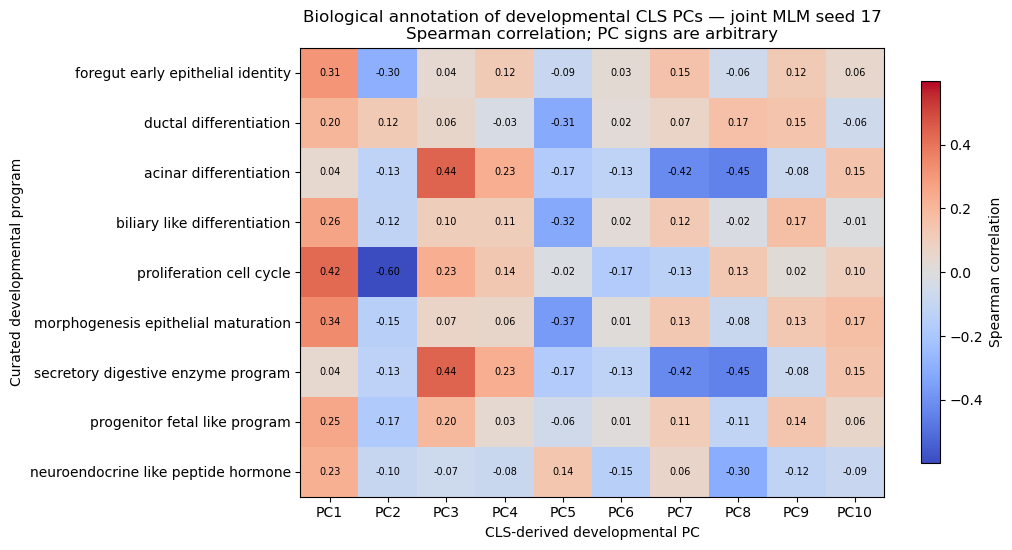

pc,1,2,3,4,5,6,7,8,9,10
program,,,,,,,,,,
foregut_early_epithelial_identity,0.313,-0.295,0.037,0.121,-0.086,0.032,0.154,-0.062,0.117,0.056
ductal_differentiation,0.205,0.119,0.060,-0.029,-0.315,0.023,0.070,0.167,0.148,-0.063
acinar_differentiation,0.045,-0.125,0.436,0.233,-0.172,-0.126,-0.418,-0.446,-0.083,0.150
biliary_like_differentiation,0.262,-0.117,0.104,0.105,-0.319,0.023,0.122,-0.021,0.169,-0.006
proliferation_cell_cycle,0.421,-0.598,0.231,0.135,-0.017,-0.169,-0.132,0.130,0.019,0.097
morphogenesis_epithelial_maturation,0.336,-0.148,0.067,0.061,-0.368,0.012,0.128,-0.081,0.128,0.173
secretory_digestive_enzyme_program,0.045,-0.127,0.437,0.230,-0.172,-0.125,-0.421,-0.448,-0.083,0.152
progenitor_fetal_like_program,0.253,-0.173,0.195,0.033,-0.056,0.008,0.108,-0.111,0.143,0.060
neuroendocrine_like_peptide_hormone,0.228,-0.098,-0.068,-0.083,0.139,-0.147,0.062,-0.304,-0.119,-0.088


In [7]:

program_scores, program_genes_used = score_programs_from_log_matrix(
    X_log, PROGRAMS_MOUSE, gene_to_idx, min_genes=MIN_PROGRAM_GENES
)
program_scores.to_csv(
    OUTDIR / "edited_results_1_developmental_program_scores_log1pCPM.csv"
)

corr17 = correlate_pc_programs(coords17, program_scores, n_pcs=N_PCS_ANNOTATE)
corr17.to_csv(
    OUTDIR / "edited_results_1_seed17_top10_PC_program_correlations.csv",
    index=False
)

matrix17 = make_program_heatmap(
    corr17,
    seed=PRIMARY_SEED,
    outfile_stem="edited_results_1_Fig1B_seed17_devPC_program_heatmap"
)
matrix17.to_csv(
    OUTDIR / "edited_results_1_Fig1B_seed17_devPC_program_matrix.csv"
)

display(matrix17.round(3))


In [8]:

# Genome-wide gene correlations with seed-17 top 10 developmental PCs.
# Program-level correlations above are Spearman; gene-level correlations
# are Pearson on log1p library-normalized expression for efficient sparse computation.
gene_tables = []
top_gene_rows = []

feature_ids = A_dev.var_names.astype(str).to_numpy()

for j in range(N_PCS_ANNOTATE):
    r = sparse_pearson_gene_correlations(X_log, coords17[:, j])

    tab = pd.DataFrame({
        "pc": j + 1,
        "axis": f"CLS_devPC{j+1}",
        "feature_id": feature_ids,
        "gene": symbols,
        "pearson_r_log1pCPM": r,
        "abs_pearson_r_log1pCPM": np.abs(r),
        "detection_fraction": detection_fraction,
    })

    eligible = tab[
        (tab["detection_fraction"] >= MIN_GENE_DETECTION_FRACTION) &
        np.isfinite(tab["pearson_r_log1pCPM"])
    ].copy()

    pos = eligible.sort_values("pearson_r_log1pCPM", ascending=False).head(25)
    neg = eligible.sort_values("pearson_r_log1pCPM", ascending=True).head(25)

    for direction, sub in [("positive", pos), ("negative", neg)]:
        tmp = sub.copy()
        tmp["direction"] = direction
        tmp["rank_within_direction"] = np.arange(1, len(tmp) + 1)
        top_gene_rows.append(tmp)

    gene_tables.append(tab)

gene_corr17 = pd.concat(gene_tables, ignore_index=True)
top_genes17 = pd.concat(top_gene_rows, ignore_index=True)

gene_corr17.to_csv(
    OUTDIR / "edited_results_1_seed17_top10_PC_gene_correlations_log1pCPM.csv.gz",
    index=False,
    compression="gzip"
)
top_genes17.to_csv(
    OUTDIR / "edited_results_1_seed17_top_genes_by_PC.csv",
    index=False
)

for pc in range(1, N_PCS_ANNOTATE + 1):
    sub = top_genes17[top_genes17["pc"] == pc]
    print(f"\nCLS_devPC{pc}")
    print("  positive:", ", ".join(sub[sub["direction"]=="positive"].head(10)["gene"]))
    print("  negative:", ", ".join(sub[sub["direction"]=="negative"].head(10)["gene"]))



CLS_devPC1
  positive: Exoc4, Tcf12, Hnrnpa2b1, Phip, Stag1, Nedd4, Rfx3, Tnks, Pard3, Pkp4
  negative: Neat1, Sftpb, Sftpd, Anxa3, Slc34a2, Tspan11, Socs2, Atp6v0a4, Zbtb16, Selenbp1

CLS_devPC2
  positive: Neat1, Acox1, Taok3, Hmgcs2, Dpyd, Thrb, Ppara, Nr1h4, Ablim1, Acsl1
  negative: Mdk, Prtg, Hmga2, Vcan, Slc2a3, Gpc6, Sox11, Kif26b, Fras1, Robo2

CLS_devPC3
  positive: Gata4, Pnliprp1, Ghr, Ctrb1, Naaladl2, Cpa2, Esrrg, Plcb1, Lrrc7, Cym
  negative: Nckap5, Limch1, Sftpc, Sftpb, Col4a2, Npnt, Atp11a, Ctsh, Col4a1, Timp3

CLS_devPC4
  positive: Muc13, Mamdc4, Prkg2, Pde3a, Pcsk5, Myo7b, Eps8l3, Cdh17, Mgam, Cubn
  negative: Foxp2, Alcam, Arhgap24, Pbx1, Mecom, Rbms3, Cadps2, Qki, Ttc6, Sema3e

CLS_devPC5
  positive: Itih3, Fn1, Fgb, Ahsg, Kng1, Abca8b, Pzp, Fga, Crp, Fgg
  negative: Mecom, Atp8a1, Adamtsl1, Tinag, Ndnf, Sftpc, Myo5c, Lmo7, Iqgap1, Cldn18

CLS_devPC6
  positive: Peg3, Sox5, Itih3, Fgb, 9030622O22Rik, Rbp4, Ahsg, Kng1, Igf2, Grb10
  negative: Cdh4, Trp63, Tnc, Bcl


## Explicit check of the previous manuscript wording

The old text mentioned:

- `CLS_devPC3`: proliferation/cell-cycle, epithelial maturation, foregut/early epithelial, biliary-like and ductal programs; gene example `Mki67`.
- `CLS_devPC10`: acinar differentiation / digestive-enzyme programs on one side and `Col4a1`, `Col4a2`, `Fn1`, `Trp63`, `Sulf1` on the other.

The following tables answer two different questions:

1. **Same-PC check:** do those old statements still hold specifically for PC3 or PC10?
2. **Biology-recovery check:** if the PC number changed, which of the first 10 PCs now carries that program/gene most strongly?

The second check is important because PCA axes can reorder or flip after retraining.


In [9]:

legacy_programs = [
    "proliferation_cell_cycle",
    "morphogenesis_epithelial_maturation",
    "foregut_early_epithelial_identity",
    "biliary_like_differentiation",
    "ductal_differentiation",
    "acinar_differentiation",
    "secretory_digestive_enzyme_program",
]
legacy_genes = ["Mki67", "Col4a1", "Col4a2", "Fn1", "Trp63", "Sulf1"]

prog_rows = []
for pname in legacy_programs:
    sub = corr17[corr17["program"] == pname].copy()
    best = sub.loc[sub["abs_spearman_r"].idxmax()]
    p3 = sub.loc[sub["pc"] == 3, "spearman_r"]
    p10 = sub.loc[sub["pc"] == 10, "spearman_r"]
    prog_rows.append({
        "program": pname,
        "old_relevant_pc": (
            "PC3" if pname in [
                "proliferation_cell_cycle",
                "morphogenesis_epithelial_maturation",
                "foregut_early_epithelial_identity",
                "biliary_like_differentiation",
                "ductal_differentiation",
            ] else "PC10"
        ),
        "seed17_PC3_spearman": float(p3.iloc[0]) if len(p3) else np.nan,
        "seed17_PC10_spearman": float(p10.iloc[0]) if len(p10) else np.nan,
        "seed17_best_top10_PC": int(best["pc"]),
        "seed17_best_top10_spearman": float(best["spearman_r"]),
        "seed17_best_top10_abs_spearman": float(best["abs_spearman_r"]),
    })

legacy_program_check = pd.DataFrame(prog_rows)
legacy_program_check.to_csv(
    OUTDIR / "edited_results_1_legacy_program_claim_check_seed17.csv",
    index=False
)

gene_rows = []
for g in legacy_genes:
    sub = gene_corr17[gene_corr17["gene"] == g].copy()

    if len(sub) == 0:
        gene_rows.append({
            "gene": g,
            "old_relevant_pc": "PC3" if g == "Mki67" else "PC10",
            "n_aligned_features_with_symbol": 0,
            "seed17_PC3_pearson": np.nan,
            "seed17_PC10_pearson": np.nan,
            "seed17_best_top10_PC": np.nan,
            "seed17_best_top10_pearson": np.nan,
            "seed17_best_top10_abs_pearson": np.nan,
        })
        continue

    by_pc = (
        sub.sort_values("abs_pearson_r_log1pCPM", ascending=False)
        .groupby("pc", as_index=False)
        .first()
    )
    best = by_pc.loc[by_pc["abs_pearson_r_log1pCPM"].idxmax()]
    p3 = by_pc.loc[by_pc["pc"] == 3, "pearson_r_log1pCPM"]
    p10 = by_pc.loc[by_pc["pc"] == 10, "pearson_r_log1pCPM"]

    gene_rows.append({
        "gene": g,
        "old_relevant_pc": "PC3" if g == "Mki67" else "PC10",
        "n_aligned_features_with_symbol": int(sub["feature_id"].nunique()),
        "seed17_PC3_pearson": float(p3.iloc[0]) if len(p3) else np.nan,
        "seed17_PC10_pearson": float(p10.iloc[0]) if len(p10) else np.nan,
        "seed17_best_top10_PC": int(best["pc"]),
        "seed17_best_top10_pearson": float(best["pearson_r_log1pCPM"]),
        "seed17_best_top10_abs_pearson": float(best["abs_pearson_r_log1pCPM"]),
    })

legacy_gene_check = pd.DataFrame(gene_rows)
legacy_gene_check.to_csv(
    OUTDIR / "edited_results_1_legacy_gene_claim_check_seed17.csv",
    index=False
)

print("Legacy program claims:")
display(legacy_program_check.round(3))
print("\nLegacy gene claims:")
display(legacy_gene_check.round(3))


Legacy program claims:


,program,old_relevant_pc,seed17_PC3_spearman,seed17_PC10_spearman,seed17_best_top10_PC,seed17_best_top10_spearman,seed17_best_top10_abs_spearman
0,proliferation_cell_cycle,PC3,0.231,0.097,2,-0.598,0.598
1,morphogenesis_epithelial_maturation,PC3,0.067,0.173,5,-0.368,0.368
2,foregut_early_epithelial_identity,PC3,0.037,0.056,1,0.313,0.313
3,biliary_like_differentiation,PC3,0.104,-0.006,5,-0.319,0.319
4,ductal_differentiation,PC3,0.060,-0.063,5,-0.315,0.315
5,acinar_differentiation,PC10,0.436,0.150,8,-0.446,0.446
6,secretory_digestive_enzyme_program,PC10,0.437,0.152,8,-0.448,0.448



Legacy gene claims:


,gene,old_relevant_pc,n_aligned_features_with_symbol,seed17_PC3_pearson,seed17_PC10_pearson,seed17_best_top10_PC,seed17_best_top10_pearson,seed17_best_top10_abs_pearson
0,Mki67,PC3,1,0.251,0.107,2,-0.424,0.424
1,Col4a1,PC10,1,-0.338,0.189,3,-0.338,0.338
2,Col4a2,PC10,1,-0.356,0.215,3,-0.356,0.356
3,Fn1,PC10,1,-0.157,0.199,5,0.652,0.652
4,Trp63,PC10,1,-0.182,0.198,6,-0.397,0.397
5,Sulf1,PC10,1,-0.226,0.101,6,-0.256,0.256



## Independent-seed robustness

The primary manuscript figure should remain seed 17 because this is the primary audited joint representation. Seed 42 is used only to ask whether the **same broad biological programs are present somewhere among the leading developmental PCs**.

We deliberately do not match `PC3` to `PC3` across seeds. PCA orientation and ordering are not expected to be invariant.


Seed 42 K at 90%: 34
Seed 42 K at 95%: 46
Seed 42 cumulative variance at K=75: 0.980711042881012


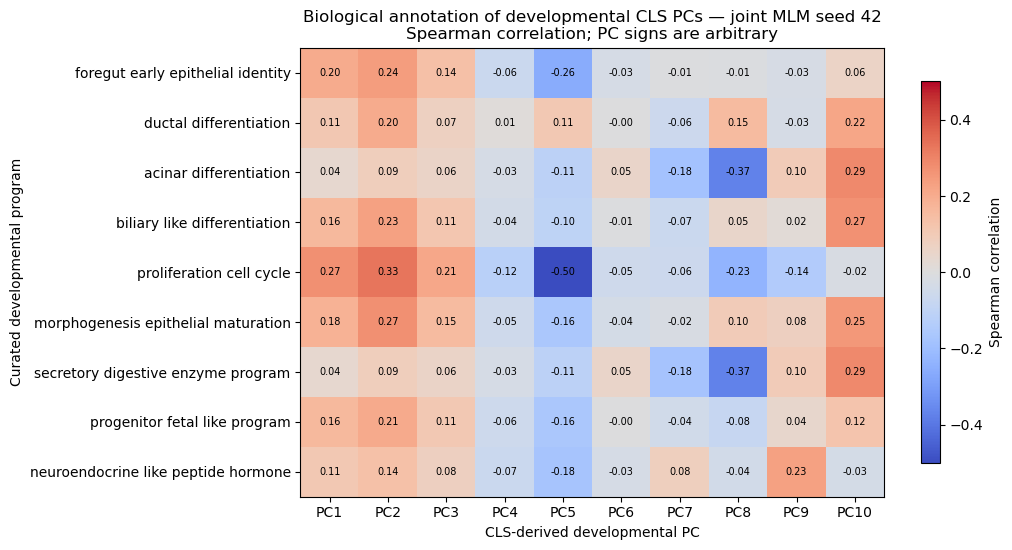

,program,seed17_best_PC,seed17_rho,seed17_max_abs_rho,seed42_best_PC,seed42_rho,seed42_max_abs_rho,min_max_abs_rho_across_seeds
7,proliferation_cell_cycle,2,-0.598,0.598,5,-0.501,0.501,0.501
8,secretory_digestive_enzyme_program,8,-0.448,0.448,8,-0.373,0.373,0.373
0,acinar_differentiation,8,-0.446,0.446,8,-0.372,0.372,0.372
4,morphogenesis_epithelial_maturation,5,-0.368,0.368,2,0.272,0.272,0.272
1,biliary_like_differentiation,5,-0.319,0.319,10,0.269,0.269,0.269
3,foregut_early_epithelial_identity,1,0.313,0.313,5,-0.261,0.261,0.261
5,neuroendocrine_like_peptide_hormone,8,-0.304,0.304,9,0.227,0.227,0.227
2,ductal_differentiation,5,-0.315,0.315,10,0.219,0.219,0.219
6,progenitor_fetal_like_program,1,0.253,0.253,2,0.206,0.206,0.206


In [10]:

mu42, pca42, coords42 = fit_dev_pca(X_dev42)
cum42 = np.cumsum(pca42.explained_variance_ratio_)

k90_42 = int(np.searchsorted(cum42, 0.90) + 1)
k95_42 = int(np.searchsorted(cum42, 0.95) + 1)
var75_42 = float(cum42[K_FIXED - 1])

print("Seed 42 K at 90%:", k90_42)
print("Seed 42 K at 95%:", k95_42)
print("Seed 42 cumulative variance at K=75:", var75_42)

variance42 = pd.DataFrame({
    "pc": np.arange(1, len(pca42.explained_variance_ratio_) + 1),
    "explained_variance_ratio": pca42.explained_variance_ratio_,
    "cumulative_variance": cum42,
})
variance42.to_csv(OUTDIR / "edited_results_1_seed42_devPCA_variance.csv", index=False)

corr42 = correlate_pc_programs(coords42, program_scores, n_pcs=N_PCS_ANNOTATE)
corr42.to_csv(
    OUTDIR / "edited_results_1_seed42_top10_PC_program_correlations.csv",
    index=False
)

matrix42 = make_program_heatmap(
    corr42,
    seed=ROBUSTNESS_SEED,
    outfile_stem="edited_results_1_seed42_devPC_program_heatmap"
)
matrix42.to_csv(
    OUTDIR / "edited_results_1_seed42_devPC_program_matrix.csv"
)

def best_program_pc(corr, seed):
    rows = []
    for pname, sub in corr.groupby("program"):
        best = sub.loc[sub["abs_spearman_r"].idxmax()]
        rows.append({
            "program": pname,
            f"seed{seed}_best_PC": int(best["pc"]),
            f"seed{seed}_rho": float(best["spearman_r"]),
            f"seed{seed}_max_abs_rho": float(best["abs_spearman_r"]),
        })
    return pd.DataFrame(rows)

best17 = best_program_pc(corr17, 17)
best42 = best_program_pc(corr42, 42)
seed_robustness = best17.merge(best42, on="program", how="outer")
seed_robustness["min_max_abs_rho_across_seeds"] = seed_robustness[
    ["seed17_max_abs_rho", "seed42_max_abs_rho"]
].min(axis=1)

seed_robustness = seed_robustness.sort_values(
    "min_max_abs_rho_across_seeds", ascending=False
)
seed_robustness.to_csv(
    OUTDIR / "edited_results_1_program_recovery_across_joint_seeds.csv",
    index=False
)

display(seed_robustness.round(3))



## Compact manuscript-oriented annotation summary

This table is intended to support rewriting the final paragraph of Results subsection 1. It reports, for each primary seed-17 PC:

- the three strongest curated program associations by absolute Spearman correlation;
- the leading positive and negative normalized-expression genes.

Use this table to choose examples that are genuinely present in the definitive model. Do **not** preserve `PC3` or `PC10` simply for continuity with the previous manuscript if the new annotation points elsewhere.


In [11]:

summary_rows = []

for pc in range(1, N_PCS_ANNOTATE + 1):
    p = corr17[corr17["pc"] == pc].sort_values("abs_spearman_r", ascending=False).head(3)

    tg = top_genes17[top_genes17["pc"] == pc]
    pos = tg[tg["direction"] == "positive"].head(10)
    neg = tg[tg["direction"] == "negative"].head(10)

    summary_rows.append({
        "pc": pc,
        "axis": f"CLS_devPC{pc}",
        "explained_variance_ratio": float(pca17.explained_variance_ratio_[pc-1]),
        "top_programs": "; ".join(
            f"{r.program}: rho={r.spearman_r:.3f}" for r in p.itertuples()
        ),
        "top_positive_genes": ", ".join(pos["gene"].astype(str)),
        "top_negative_genes": ", ".join(neg["gene"].astype(str)),
    })

annotation_summary = pd.DataFrame(summary_rows)
annotation_summary.to_csv(
    OUTDIR / "edited_results_1_seed17_PC_annotation_summary.csv",
    index=False
)
display(annotation_summary)


,pc,axis,explained_variance_ratio,top_programs,top_positive_genes,top_negative_genes
0,1,CLS_devPC1,0.114303,proliferation_cell_cycle: rho=0.421; morphogen...,"Exoc4, Tcf12, Hnrnpa2b1, Phip, Stag1, Nedd4, R...","Neat1, Sftpb, Sftpd, Anxa3, Slc34a2, Tspan11, ..."
1,2,CLS_devPC2,0.089585,proliferation_cell_cycle: rho=-0.598; foregut_...,"Neat1, Acox1, Taok3, Hmgcs2, Dpyd, Thrb, Ppara...","Mdk, Prtg, Hmga2, Vcan, Slc2a3, Gpc6, Sox11, K..."
2,3,CLS_devPC3,0.065271,secretory_digestive_enzyme_program: rho=0.437;...,"Gata4, Pnliprp1, Ghr, Ctrb1, Naaladl2, Cpa2, E...","Nckap5, Limch1, Sftpc, Sftpb, Col4a2, Npnt, At..."
3,4,CLS_devPC4,0.054640,acinar_differentiation: rho=0.233; secretory_d...,"Muc13, Mamdc4, Prkg2, Pde3a, Pcsk5, Myo7b, Eps...","Foxp2, Alcam, Arhgap24, Pbx1, Mecom, Rbms3, Ca..."
4,5,CLS_devPC5,0.052896,morphogenesis_epithelial_maturation: rho=-0.36...,"Itih3, Fn1, Fgb, Ahsg, Kng1, Abca8b, Pzp, Fga,...","Mecom, Atp8a1, Adamtsl1, Tinag, Ndnf, Sftpc, M..."
5,6,CLS_devPC6,0.051262,proliferation_cell_cycle: rho=-0.169; neuroend...,"Peg3, Sox5, Itih3, Fgb, 9030622O22Rik, Rbp4, A...","Cdh4, Trp63, Tnc, Bcl2, Prss16, Camk4, Slc46a2..."
6,7,CLS_devPC7,0.047842,secretory_digestive_enzyme_program: rho=-0.421...,"Bpifb1, Lypd6b, Anxa10, Fgf14, Cym, Pga5, Efna...","Rbpjl, Meg3, Pnliprp1, Ctrb1, Ccbe1, Cpa2, Dlk..."
7,8,CLS_devPC8,0.044528,secretory_digestive_enzyme_program: rho=-0.448...,"Nckap5, Foxp2, Dpyd, Fbn2, Ndnf, Magi3, Lama3,...","Meis2, Pclo, Cacna1d, Rap1gap2, Slit3, Pnliprp..."
8,9,CLS_devPC9,0.042262,biliary_like_differentiation: rho=0.169; ducta...,"Bpifb1, Cym, Ptprk, Anxa10, Pga5, Pdgfd, Sema3...","Cdh4, Trp63, Nfia, Tnc, Prss16, Camk4, Pltp, R..."
9,10,CLS_devPC10,0.039276,morphogenesis_epithelial_maturation: rho=0.173...,"Timp3, Tg, Rtkn2, Col4a4, Ahnak, Ager, Pax8, R...","Tmem163, Rimbp2, Slc34a2, Pcsk2, Cacna1a, Inpp..."


In [12]:

expected_files = [
    "edited_results_1_program_marker_coverage.csv",
    "edited_results_1_seed17_devPCA_variance.csv",
    "edited_results_1_developmental_program_scores_log1pCPM.csv",
    "edited_results_1_seed17_top10_PC_program_correlations.csv",
    "edited_results_1_Fig1B_seed17_devPC_program_matrix.csv",
    "edited_results_1_Fig1B_seed17_devPC_program_heatmap.pdf",
    "edited_results_1_Fig1B_seed17_devPC_program_heatmap.png",
    "edited_results_1_seed17_top10_PC_gene_correlations_log1pCPM.csv.gz",
    "edited_results_1_seed17_top_genes_by_PC.csv",
    "edited_results_1_legacy_program_claim_check_seed17.csv",
    "edited_results_1_legacy_gene_claim_check_seed17.csv",
    "edited_results_1_seed42_devPCA_variance.csv",
    "edited_results_1_seed42_top10_PC_program_correlations.csv",
    "edited_results_1_seed42_devPC_program_matrix.csv",
    "edited_results_1_seed42_devPC_program_heatmap.pdf",
    "edited_results_1_seed42_devPC_program_heatmap.png",
    "edited_results_1_program_recovery_across_joint_seeds.csv",
    "edited_results_1_seed17_PC_annotation_summary.csv",
]

missing = [fn for fn in expected_files if not (OUTDIR / fn).exists()]

audit = {
    "analysis": "edited_results_1_developmental_PC_annotation",
    "audited_root": str(AUDITED_ROOT),
    "development_h5ad": str(DEV_H5AD),
    "primary_joint_seed": PRIMARY_SEED,
    "primary_model_dir": str(MODEL17),
    "robustness_joint_seed": ROBUSTNESS_SEED,
    "robustness_model_dir": str(MODEL42),
    "n_development_cells": int(A_dev.n_obs),
    "n_genes": int(A_dev.n_vars),
    "embedding_dimension": int(X_dev17.shape[1]),
    "expression_for_annotation": "log1p(counts/library_size*1e4)",
    "program_correlation": "Spearman",
    "gene_correlation": "Pearson on log1p library-normalized expression",
    "n_pcs_annotated": N_PCS_ANNOTATE,
    "seed17_K90": k90_17,
    "seed17_K95": k95_17,
    "seed17_variance_K75": var75_17,
    "seed42_K90": k90_42,
    "seed42_K95": k95_42,
    "seed42_variance_K75": var75_42,
    "expected_outputs": expected_files,
    "missing_outputs": missing,
    "status": "PASS" if not missing else "FAIL",
}

with open(OUTDIR / "edited_results_1_audit_manifest.json", "w") as f:
    json.dump(audit, f, indent=2)

print("\nGenerated files:")
for fn in sorted(expected_files + ["edited_results_1_audit_manifest.json"]):
    p = OUTDIR / fn
    print(" -", p, "[OK]" if p.exists() else "[MISSING]")

print("\nEDITED RESULTS 1 AUDIT STATUS:", audit["status"])
if missing:
    raise RuntimeError(f"Missing expected outputs: {missing}")



Generated files:
 - /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_results_1_developmental_PC_annotation/edited_results_1_Fig1B_seed17_devPC_program_heatmap.pdf [OK]
 - /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_results_1_developmental_PC_annotation/edited_results_1_Fig1B_seed17_devPC_program_heatmap.png [OK]
 - /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_results_1_developmental_PC_annotation/edited_results_1_Fig1B_seed17_devPC_program_matrix.csv [OK]
 - /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_results_1_developmental_PC_annotation/edited_results_1_audit_manifest.json [OK]
 - /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_results_1_developmental_PC_annotation/edited_results_1_developmental_program_scores_log1pCPM.csv [OK]
 - /home/jfpoy